In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


- Why do EDA 
    - Model Building
    - Analysis and Reporting
    - Validate assumptions
    - Hnadling missing Values
    - Features Engineering
    - Detecting Outliers

In [2]:
df = pd.read_csv('Car Sales.xlsx - car_data.csv')

In [3]:
df.head()

,Car_id,Date,Customer Name,Gender,Annual Income,Dealer_Name,Company,Model,Engine,Transmission,Color,Price ($),Dealer_No,Body Style,Phone,Dealer_Region
0,C_CND_000001,1/2/2022,Geraldine,Male,13500,Buddy Storbeck's Diesel Service Inc,Ford,Expedition,DoubleÂ Overhead Camshaft,Auto,Black,26000,06457-3834,SUV,8264678,Middletown
1,C_CND_000002,1/2/2022,Gia,Male,1480000,C & M Motors Inc,Dodge,Durango,DoubleÂ Overhead Camshaft,Auto,Black,19000,60504-7114,SUV,6848189,Aurora
2,C_CND_000003,1/2/2022,Gianna,Male,1035000,Capitol KIA,Cadillac,Eldorado,Overhead Camshaft,Manual,Red,31500,38701-8047,Passenger,7298798,Greenville
3,C_CND_000004,1/2/2022,Giselle,Male,13500,Chrysler of Tri-Cities,Toyota,Celica,Overhead Camshaft,Manual,Pale White,14000,99301-3882,SUV,6257557,Pasco
4,C_CND_000005,1/2/2022,Grace,Male,1465000,Chrysler Plymouth,Acura,TL,DoubleÂ Overhead Camshaft,Auto,Red,24500,53546-9427,Hatchback,7081483,Janesville


Understanding Data and Structure

- Rows -> 23906
- Customer name - > 1 missing Values
- Date -> String (DATETIME)


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23906 entries, 0 to 23905
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   Car_id         23906 non-null  object
 1   Date           23906 non-null  object
 2   Customer Name  23905 non-null  object
 3   Gender         23906 non-null  object
 4   Annual Income  23906 non-null  int64 
 5   Dealer_Name    23906 non-null  object
 6   Company        23906 non-null  object
 7   Model          23906 non-null  object
 8   Engine         23906 non-null  object
 9   Transmission   23906 non-null  object
 10  Color          23906 non-null  object
 11  Price ($)      23906 non-null  int64 
 12  Dealer_No      23906 non-null  object
 13  Body Style     23906 non-null  object
 14  Phone          23906 non-null  int64 
 15  Dealer_Region  23906 non-null  object
dtypes: int64(3), object(13)
memory usage: 2.9+ MB


In [5]:
df.shape

(23906, 16)

- Checking Missing Values & Duplicates



- Customer Name - 1 Missing Value

In [6]:
df.isnull().sum() # Check missing values

Car_id           0
Date             0
Customer Name    1
Gender           0
Annual Income    0
Dealer_Name      0
Company          0
Model            0
Engine           0
Transmission     0
Color            0
Price ($)        0
Dealer_No        0
Body Style       0
Phone            0
Dealer_Region    0
dtype: int64

In [7]:
df[df['Customer Name'].isnull()] # this customer name is null

,Car_id,Date,Customer Name,Gender,Annual Income,Dealer_Name,Company,Model,Engine,Transmission,Color,Price ($),Dealer_No,Body Style,Phone,Dealer_Region
7564,C_CND_007565,11/5/2022,NaN,Male,680000,Saab-Belle Dodge,Dodge,Ram Pickup,DoubleÂ Overhead Camshaft,Auto,Pale White,45000,60504-7114,Hardtop,7203103,Aurora


In [8]:
df.duplicated().sum() # checking duplicated values

np.int64(0)

- Statistical Summary

In [9]:
df.describe()

,Annual Income,Price ($),Phone
count,2.390600e+04,23906.000000,2.390600e+04
mean,8.308403e+05,28090.247846,7.497741e+06
std,7.200064e+05,14788.687608,8.674920e+05
min,1.008000e+04,1200.000000,6.000101e+06
25%,3.860000e+05,18001.000000,6.746495e+06
50%,7.350000e+05,23000.000000,7.496198e+06
75%,1.175750e+06,34000.000000,8.248146e+06
max,1.120000e+07,85800.000000,8.999579e+06


In [10]:
pd.set_option('display.float_format','{:,.0f}'.format) # this is used to fix scientific notation values into normal values

df.describe()

,Annual Income,Price ($),Phone
count,"23,906","23,906","23,906"
mean,"830,840","28,090","7,497,741"
std,"720,006","14,789","867,492"
min,"10,080","1,200","6,000,101"
25%,"386,000","18,001","6,746,495"
50%,"735,000","23,000","7,496,198"
75%,"1,175,750","34,000","8,248,146"
max,"11,200,000","85,800","8,999,579"


- Fill Missing  Value & Change Date coloumn into DateTime object

In [11]:
df['Customer Name'].fillna('Unkonwn',inplace=True)

C:\Users\MD ARBAZ\AppData\Local\Temp\ipykernel_3584\559353370.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Customer Name'].fillna('Unkonwn',inplace=True)


In [12]:
df['Customer Name'].isnull().sum()

np.int64(0)

In [13]:
# Change date column str into Date time 
df['Date'] = pd.to_datetime(df['Date'])

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23906 entries, 0 to 23905
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Car_id         23906 non-null  object        
 1   Date           23906 non-null  datetime64[ns]
 2   Customer Name  23906 non-null  object        
 3   Gender         23906 non-null  object        
 4   Annual Income  23906 non-null  int64         
 5   Dealer_Name    23906 non-null  object        
 6   Company        23906 non-null  object        
 7   Model          23906 non-null  object        
 8   Engine         23906 non-null  object        
 9   Transmission   23906 non-null  object        
 10  Color          23906 non-null  object        
 11  Price ($)      23906 non-null  int64         
 12  Dealer_No      23906 non-null  object        
 13  Body Style     23906 non-null  object        
 14  Phone          23906 non-null  int64         
 15  Dealer_Region  2390

- Cleaning Proceses

In [15]:
df.head()

,Car_id,Date,Customer Name,Gender,Annual Income,Dealer_Name,Company,Model,Engine,Transmission,Color,Price ($),Dealer_No,Body Style,Phone,Dealer_Region
0,C_CND_000001,2022-01-02,Geraldine,Male,13500,Buddy Storbeck's Diesel Service Inc,Ford,Expedition,DoubleÂ Overhead Camshaft,Auto,Black,26000,06457-3834,SUV,8264678,Middletown
1,C_CND_000002,2022-01-02,Gia,Male,1480000,C & M Motors Inc,Dodge,Durango,DoubleÂ Overhead Camshaft,Auto,Black,19000,60504-7114,SUV,6848189,Aurora
2,C_CND_000003,2022-01-02,Gianna,Male,1035000,Capitol KIA,Cadillac,Eldorado,Overhead Camshaft,Manual,Red,31500,38701-8047,Passenger,7298798,Greenville
3,C_CND_000004,2022-01-02,Giselle,Male,13500,Chrysler of Tri-Cities,Toyota,Celica,Overhead Camshaft,Manual,Pale White,14000,99301-3882,SUV,6257557,Pasco
4,C_CND_000005,2022-01-02,Grace,Male,1465000,Chrysler Plymouth,Acura,TL,DoubleÂ Overhead Camshaft,Auto,Red,24500,53546-9427,Hatchback,7081483,Janesville


- Clean Engine Column Replacing Formatting issues and extra characters in the engine column

In [16]:
df['Engine'] = df['Engine'].str.replace('DoubleÂ','Double',regex=False) # Rplace extra char from engine column

In [17]:
df.head()

,Car_id,Date,Customer Name,Gender,Annual Income,Dealer_Name,Company,Model,Engine,Transmission,Color,Price ($),Dealer_No,Body Style,Phone,Dealer_Region
0,C_CND_000001,2022-01-02,Geraldine,Male,13500,Buddy Storbeck's Diesel Service Inc,Ford,Expedition,Double Overhead Camshaft,Auto,Black,26000,06457-3834,SUV,8264678,Middletown
1,C_CND_000002,2022-01-02,Gia,Male,1480000,C & M Motors Inc,Dodge,Durango,Double Overhead Camshaft,Auto,Black,19000,60504-7114,SUV,6848189,Aurora
2,C_CND_000003,2022-01-02,Gianna,Male,1035000,Capitol KIA,Cadillac,Eldorado,Overhead Camshaft,Manual,Red,31500,38701-8047,Passenger,7298798,Greenville
3,C_CND_000004,2022-01-02,Giselle,Male,13500,Chrysler of Tri-Cities,Toyota,Celica,Overhead Camshaft,Manual,Pale White,14000,99301-3882,SUV,6257557,Pasco
4,C_CND_000005,2022-01-02,Grace,Male,1465000,Chrysler Plymouth,Acura,TL,Double Overhead Camshaft,Auto,Red,24500,53546-9427,Hatchback,7081483,Janesville


- Rename columns name cleaning up column names by removing spaces and special characters for better readability

In [18]:
df=df.rename(columns={
    'Car_id	':'car_id',
    'Date': 'date',
    'Customer Name' : 'customer_name',
    'Gender':'gender',
    'Annual Income':'annual_income',
    'Dealer_Name':'dealer_name',
    'Company':'company',
    'Model':'model',
    'Engine':'engine',
    'Transmission':'transmission',
    'Color':'color',
    'Price ($)':'price',
    'Dealer_No':'dealer_no',
    'Body Style':'body_style',
    'Phone':'phone',
    'Dealer_Region':'dealer_region'



})

In [19]:
df.columns

Index(['Car_id', 'date', 'customer_name', 'gender', 'annual_income',
       'dealer_name', 'company', 'model', 'engine', 'transmission', 'color',
       'price', 'Dealer_No ', 'body_style', 'phone', 'dealer_region'],
      dtype='object')

In [20]:
df['annual_income'].describe()

count       23,906
mean       830,840
std        720,006
min         10,080
25%        386,000
50%        735,000
75%      1,175,750
max     11,200,000
Name: annual_income, dtype: float64

- Feature Engineering 

- annual income segmentation categorizing customers based on statistical summary of anual income

In [21]:
bins = [0,500000,1200000,df['annual_income'].max()]
labels = ['Low Income','Medium Income','High Income']

# creating the annual segmented coloumn
df['annual_segmentaion']=pd.cut(df['annual_income'],bins=bins,labels=labels,include_lowest=True)

In [22]:
df['annual_segmentaion'].value_counts() # checking the distribution of segmentation

annual_segmentaion
Medium Income    10729
Low Income        7483
High Income       5694
Name: count, dtype: int64

In [23]:
df['price'].describe()

count   23,906
mean    28,090
std     14,789
min      1,200
25%     18,001
50%     23,000
75%     34,000
max     85,800
Name: price, dtype: float64

- Feature Engineering : Car Price Segmentation 
- Categorizing cars into Budget , Midrange and Expeensive Groups based on the  statistical distribution of car prices.

In [24]:
# define bins and labels based on price description
bins = [0,20000,40000,df['price'].max()]
labels = ['Budget','Mid-Range','Expensive']

# Creating new column price category column
df['price_category'] = pd.cut(df['price'], bins=bins,labels=labels,include_lowest=True)

In [25]:
df['price_category'].value_counts() # checking distribution of price category column

price_category
Mid-Range    10870
Budget        8348
Expensive     4688
Name: count, dtype: int64

In [26]:
df

,Car_id,date,customer_name,gender,annual_income,dealer_name,company,model,engine,transmission,color,price,Dealer_No,body_style,phone,dealer_region,annual_segmentaion,price_category
0,C_CND_000001,2022-01-02,Geraldine,Male,13500,Buddy Storbeck's Diesel Service Inc,Ford,Expedition,Double Overhead Camshaft,Auto,Black,26000,06457-3834,SUV,8264678,Middletown,Low Income,Mid-Range
1,C_CND_000002,2022-01-02,Gia,Male,1480000,C & M Motors Inc,Dodge,Durango,Double Overhead Camshaft,Auto,Black,19000,60504-7114,SUV,6848189,Aurora,High Income,Budget
2,C_CND_000003,2022-01-02,Gianna,Male,1035000,Capitol KIA,Cadillac,Eldorado,Overhead Camshaft,Manual,Red,31500,38701-8047,Passenger,7298798,Greenville,Medium Income,Mid-Range
3,C_CND_000004,2022-01-02,Giselle,Male,13500,Chrysler of Tri-Cities,Toyota,Celica,Overhead Camshaft,Manual,Pale White,14000,99301-3882,SUV,6257557,Pasco,Low Income,Budget
4,C_CND_000005,2022-01-02,Grace,Male,1465000,Chrysler Plymouth,Acura,TL,Double Overhead Camshaft,Auto,Red,24500,53546-9427,Hatchback,7081483,Janesville,High Income,Mid-Range
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23901,C_CND_023902,2023-12-31,Martin,Male,13500,C & M Motors Inc,Plymouth,Voyager,Overhead Camshaft,Manual,Red,12000,60504-7114,Passenger,8583598,Pasco,Low Income,Budget
23902,C_CND_023903,2023-12-31,Jimmy,Female,900000,Ryder Truck Rental and Leasing,Chevrolet,Prizm,Double Overhead Camshaft,Auto,Black,16000,06457-3834,Hardtop,7914229,Middletown,Medium Income,Budget
23903,C_CND_023904,2023-12-31,Emma,Male,705000,Chrysler of Tri-Cities,BMW,328i,Overhead Camshaft,Manual,Red,21000,99301-3882,Sedan,7659127,Scottsdale,Medium Income,Mid-Range
23904,C_CND_023905,2023-12-31,Victoire,Male,13500,Chrysler Plymouth,Chevrolet,Metro,Double Overhead Camshaft,Auto,Black,31000,53546-9427,Passenger,6030764,Austin,Low Income,Mid-Range


In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23906 entries, 0 to 23905
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Car_id              23906 non-null  object        
 1   date                23906 non-null  datetime64[ns]
 2   customer_name       23906 non-null  object        
 3   gender              23906 non-null  object        
 4   annual_income       23906 non-null  int64         
 5   dealer_name         23906 non-null  object        
 6   company             23906 non-null  object        
 7   model               23906 non-null  object        
 8   engine              23906 non-null  object        
 9   transmission        23906 non-null  object        
 10  color               23906 non-null  object        
 11  price               23906 non-null  int64         
 12  Dealer_No           23906 non-null  object        
 13  body_style          23906 non-null  object    

- Column Type

- Numerical - price , annual_income, phone

- Categorical - price_category, annual_segmentation, gender, engine,transmission, company , color, body_style, delear_region, dealer_name

- Mixed Column - Car_id, date , dealer_no


 Univariate Analysis 

Univariate analysis focuses on analyzing each feature in the dataset independently.\\

- **Distribution analysis**: The distribution of each feature is examined to identify its shape, central tendency, and dispersion.

- **Identifying potential issues**: Univariate analysis helps in identifying potential problems with the data such as outliers, skewness, and missing values









#### The shape of a data distribution refers to its overall pattern or form as it is represented on a graph. Some common shapes of data distributions include:

- **Normal Distribution**: A symmetrical and bell-shaped distribution where the mean, median, and mode are equal and the majority of the data falls in the middle of the distribution with gradually decreasing frequencies towards the tails.

- **Skewed Distribution**: A distribution that is not symmetrical, with one tail being longer than the other. It can be either positively skewed (right-skewed) or negatively skewed (left-skewed).

- **Bimodal Distribution**: A distribution with two peaks or modes.

- **Uniform Distribution**: A distribution where all values have an equal chance of occurring.

The shape of the data distribution is important in identifying the presence of outliers, skewness, and the type of statistical tests and models that can be used for further analysis.








#### **Dispersion** is a statistical term used to describe the spread or variability of a set of data. It measures how far the values in a data set are spread out from the central tendency (mean, median, or mode) of the data.

There are several measures of dispersion, including:

- **Range**: The difference between the largest and smallest values in a data set.

- **Variance**: The average of the squared deviations of each value from the mean of the data set.

- **Standard Deviation**: The square root of the variance. It provides a measure of the spread of the data that is in the same units as the original data.

- **Interquartile range (IQR)**: The range between the first quartile (25th percentile) and the third quartile (75th percentile) of the data.

Dispersion helps to describe the spread of the data, which can help to identify the presence of outliers and skewness in the data.







### Steps of doing Univariate Analysis on Numerical columns

- **Descriptive Statistics**: Compute basic summary statistics for the column, such as mean, median, mode, standard deviation, range, and quartiles. These statistics give a general understanding of the distribution of the data and can help identify skewness or outliers.

- **Visualizations**: Create visualizations to explore the distribution of the data. Some common visualizations for numerical data include histograms, box plots, and density plots. These visualizations provide a visual representation of the distribution of the data and can help identify skewness an outliers.

- **Identifying Outliers**: Identify and examine any outliers in the data. Outliers can be identified using visualizations. It is important to determine whether the outliers are due to measurement errors, data entry errors, or legitimate differences in the data, and to decide whether to include or exclude them from the analysis.

- **Skewness**: Check for skewness in the data and consider transforming the data or using robust statistical methods that are less sensitive to skewness, if necessary.

- **Conclusion**: Summarize the findings of the EDA and make decisions about how to proceed with further analysis.





### Price

**Conclusions**
  - There are some outliers
  - Positive skewed(1.4)
  - Right Positively Distribution

In [28]:
# Genarate descriptive statistics
df['price'].describe()

count   23,906
mean    28,090
std     14,789
min      1,200
25%     18,001
50%     23,000
75%     34,000
max     85,800
Name: price, dtype: float64

<Axes: ylabel='Frequency'>

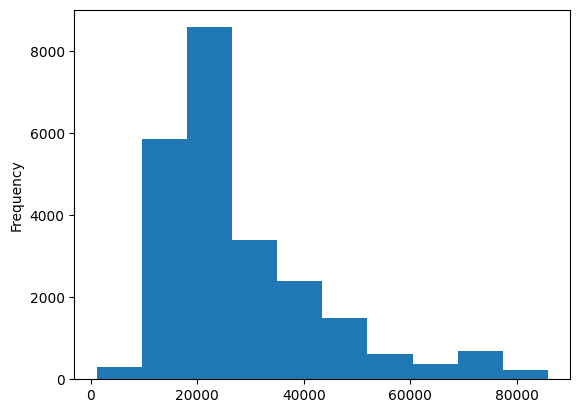

In [29]:
# Visualisations
df['price'].plot(kind='hist',bins=10)

<Axes: ylabel='Density'>

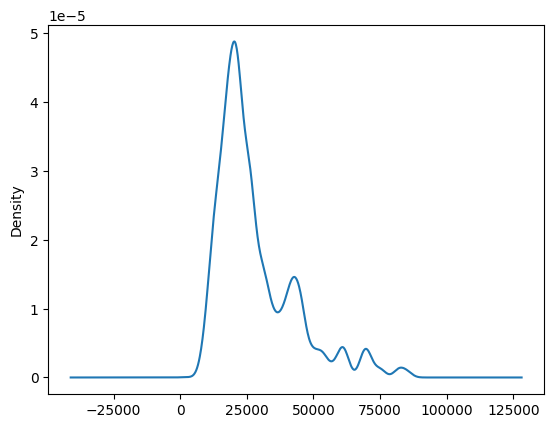

In [30]:
df['price'].plot(kind='kde')

<Axes: >

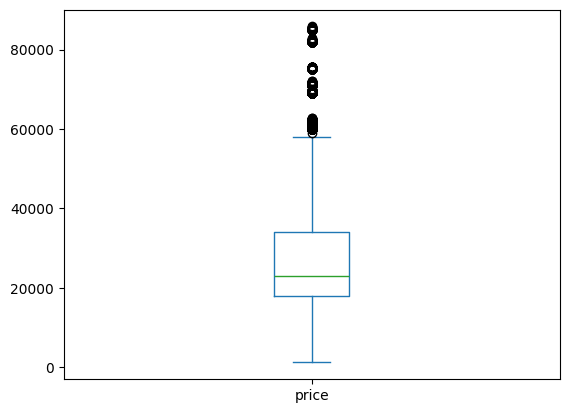

In [31]:
df['price'].plot(kind='box')

In [32]:
df['price'].skew()

np.float64(1.4663159398912697)

In [33]:
df['price'].isnull().sum()

np.int64(0)

### Annual_Income

**Conclusions**
- Highley positive skewed data (1.7)
- there are outliers

<Axes: ylabel='Frequency'>

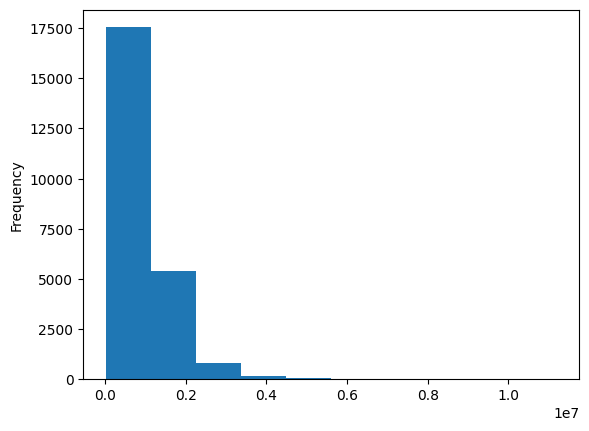

In [34]:
df['annual_income'].plot(kind='hist')

<Axes: ylabel='Density'>

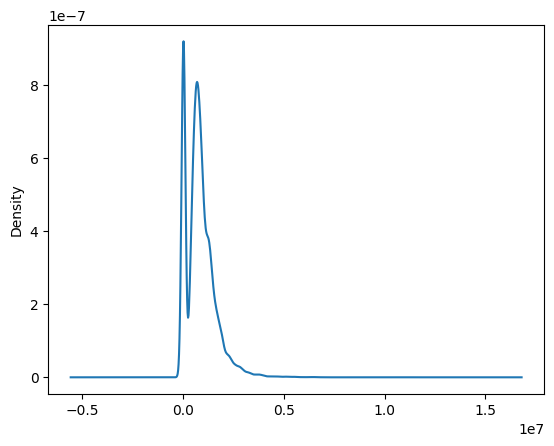

In [35]:
df['annual_income'].plot(kind='kde')

<Axes: >

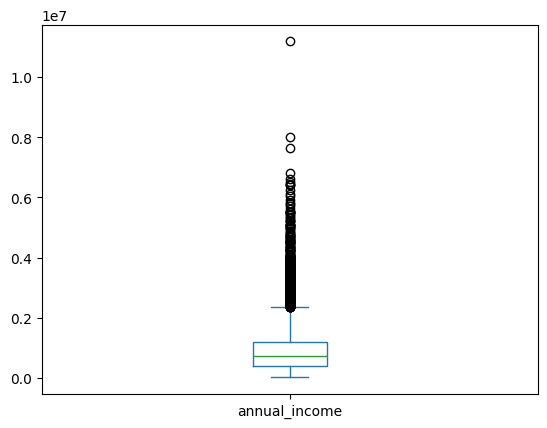

In [36]:
df['annual_income'].plot(kind='box')

In [37]:
df['annual_income'].skew()

np.float64(1.7398383620878002)

In [38]:
np.log(df['annual_income'])

0       10
1       14
2       14
3       10
4       14
        ..
23901   10
23902   14
23903   13
23904   10
23905   14
Name: annual_income, Length: 23906, dtype: float64

### Steps of doing Univariate Analysis on Categorical columns

**Descriptive Statistics**: Compute the frequency distribution of the categories in the column. This will give a general understanding of the distribution of the categories and their relative frequencies.

**Visualizations**: Create visualizations to explore the distribution of the categories. Some common visualizations for categorical data include count plots and pie charts. These visualizations provide a visual representation of the distribution of the categories and can help identify any patterns or anomalies in the data.

**Missing Values**: Check for missing values in the data and decide how to handle them. Missing values can be imputed or excluded from the analysis, depending on the research question and the data set.

**Conclusion**: Summarize the findings of the EDA and make decisions about how to proceed with further analysis.

### price_category

**Conclusions**
- 45.5% Mid-range 
- 34.9% Bdget
- 19.6% Expensive

In [39]:
df['price_category'].value_counts()

price_category
Mid-Range    10870
Budget        8348
Expensive     4688
Name: count, dtype: int64

<Axes: ylabel='count'>

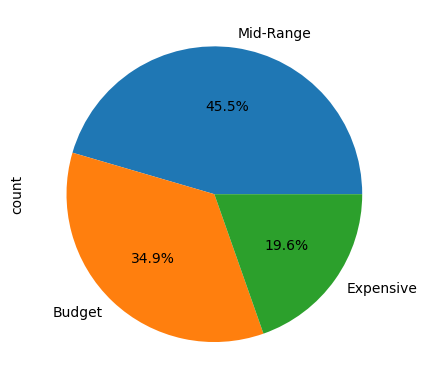

In [40]:
df['price_category'].value_counts().plot(kind='pie',autopct='%0.1f%%')

<Axes: xlabel='price_category'>

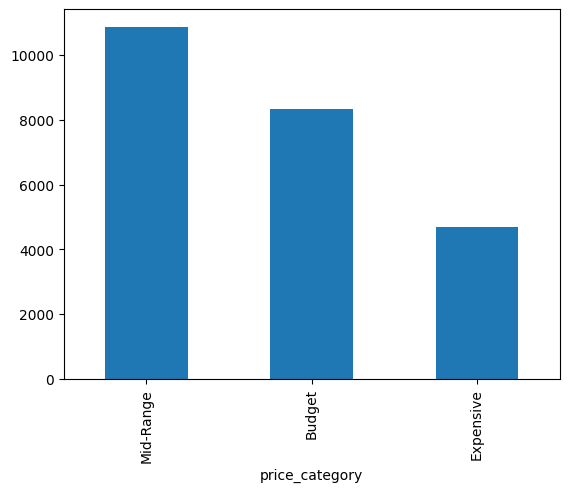

In [41]:
df['price_category'].value_counts().plot(kind='bar')

In [42]:
df['price_category'].isnull().sum()

np.int64(0)

### annual_segmentation
**Conclusions**
- 44.9% Medium Income
- 31.3% Low Income
- 23.8% High Income

In [43]:
df['annual_segmentaion'].value_counts()

annual_segmentaion
Medium Income    10729
Low Income        7483
High Income       5694
Name: count, dtype: int64

<Axes: ylabel='count'>

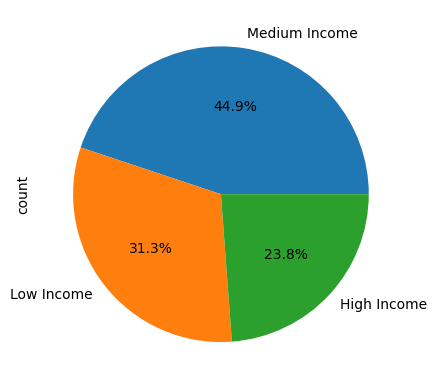

In [44]:
df['annual_segmentaion'].value_counts().plot(kind='pie',autopct='%0.1f%%')

<Axes: xlabel='annual_segmentaion'>

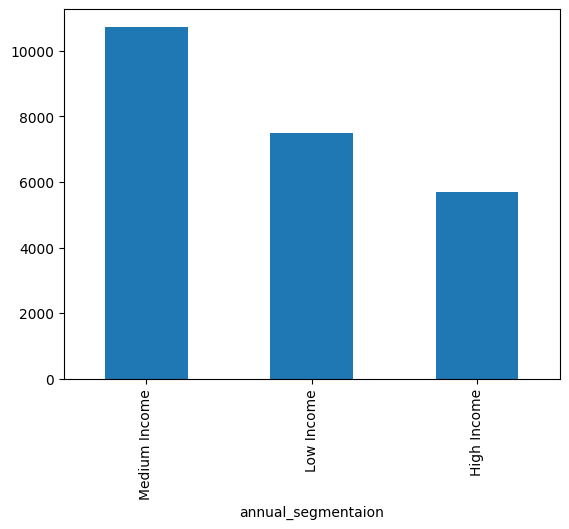

In [45]:
df['annual_segmentaion'].value_counts().plot(kind='bar')

In [46]:
df['annual_segmentaion'].isnull().sum()

np.int64(0)

### gender

**Conclusions**
- 78.6% Male customer
- 21.4% Female customer

In [47]:
df['gender'].value_counts()

gender
Male      18798
Female     5108
Name: count, dtype: int64

<Axes: ylabel='count'>

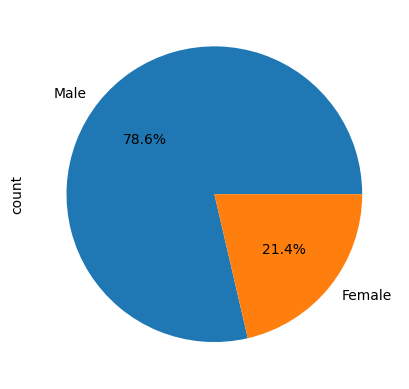

In [48]:
df['gender'].value_counts().plot(kind='pie',autopct='%0.1f%%')

<Axes: xlabel='gender'>

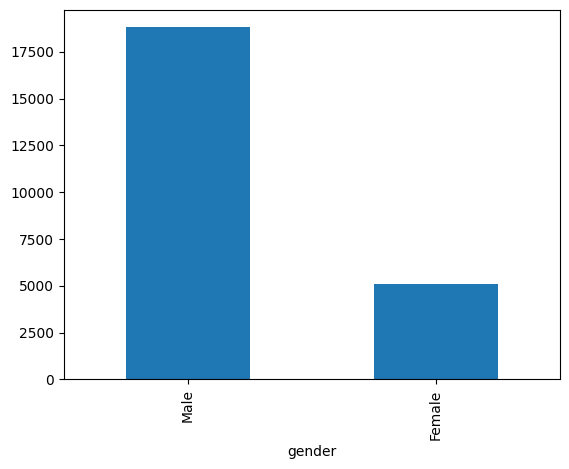

In [49]:
df['gender'].value_counts().plot(kind='bar')

In [50]:
df['gender'].isnull().sum()

np.int64(0)

### traansmission

**Conclusions**
- Auto 52.6%
- Manual 47.4%

In [51]:
df['transmission'].value_counts()

transmission
Auto      12571
Manual    11335
Name: count, dtype: int64

<Axes: ylabel='count'>

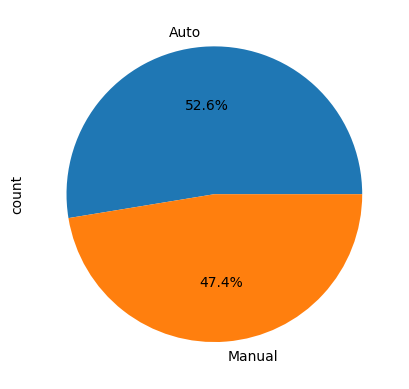

In [52]:
df['transmission'].value_counts().plot(kind='pie',autopct='%0.1f%%')

<Axes: xlabel='transmission'>

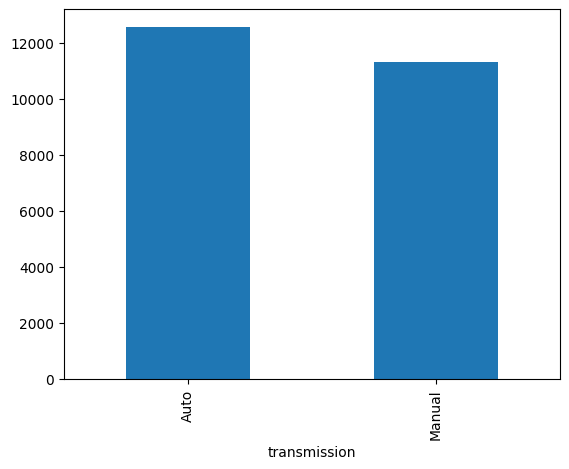

In [53]:
df['transmission'].value_counts().plot(kind='bar')

In [54]:
df['transmission'].isnull().sum()

np.int64(0)

### engine

**Conclusions**
- 53% Double Overhead Camshasft
- 47% Overhead camshaft

In [55]:
df['engine'].value_counts()

engine
Double Overhead Camshaft    12571
Overhead Camshaft           11335
Name: count, dtype: int64

<Axes: ylabel='count'>

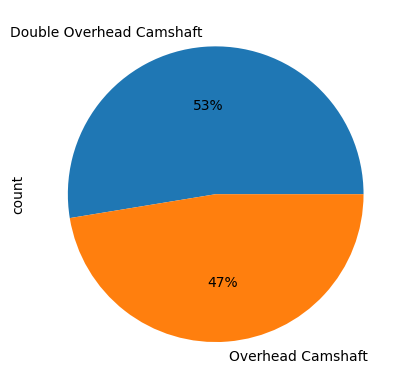

In [56]:
df['engine'].value_counts().plot(kind='pie',autopct='%1.0f%%')

<Axes: xlabel='engine'>

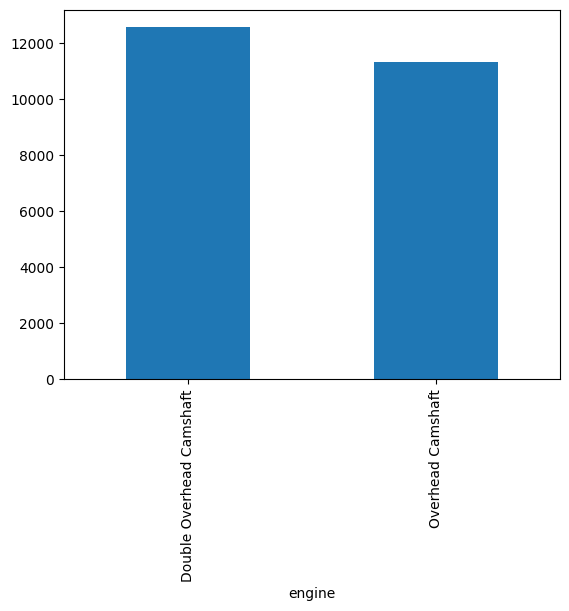

In [57]:
df['engine'].value_counts().plot(kind='bar')

In [58]:
df['engine'].isnull().sum()

np.int64(0)

### Company

**Conclusions**

In [59]:
df['company'].value_counts()

company
Chevrolet     1819
Dodge         1671
Ford          1614
Volkswagen    1333
Mercedes-B    1285
Mitsubishi    1277
Chrysler      1120
Oldsmobile    1111
Toyota        1110
Nissan         886
Mercury        874
Lexus          802
Pontiac        796
BMW            790
Volvo          789
Honda          708
Acura          689
Cadillac       652
Plymouth       617
Saturn         586
Lincoln        492
Audi           468
Buick          439
Subaru         405
Jeep           363
Porsche        361
Hyundai        264
Saab           210
Infiniti       195
Jaguar         180
Name: count, dtype: int64

<Axes: ylabel='count'>

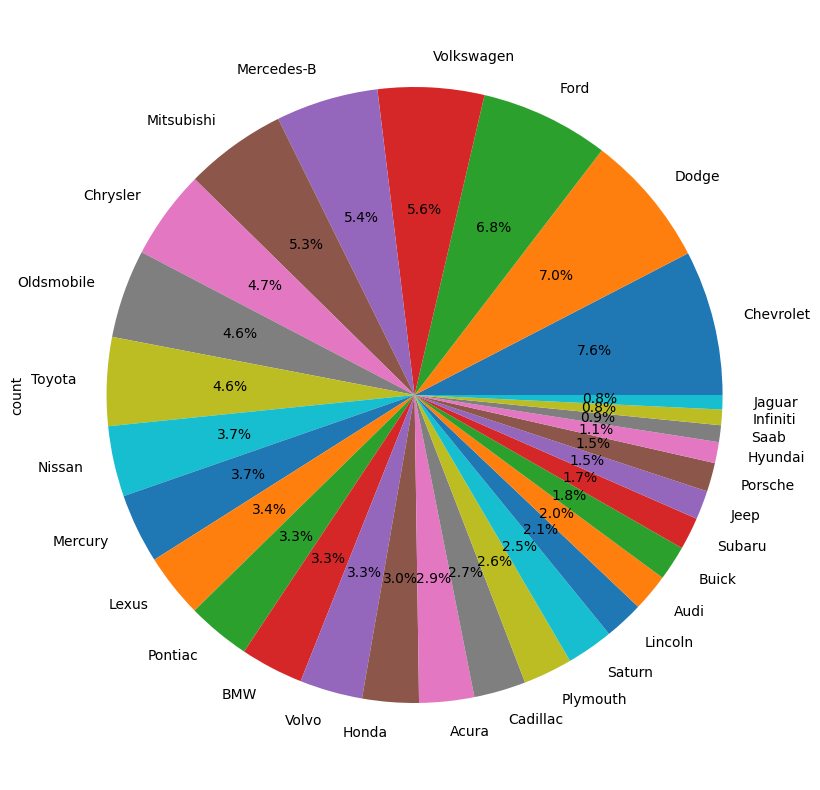

In [60]:
plt.figure(figsize=(10,10))
df['company'].value_counts().plot(kind='pie',autopct='%0.1f%%')

In [61]:
# Top 10 companies
top_companies = df['company'].value_counts().head(10)

In [62]:
top_companies

company
Chevrolet     1819
Dodge         1671
Ford          1614
Volkswagen    1333
Mercedes-B    1285
Mitsubishi    1277
Chrysler      1120
Oldsmobile    1111
Toyota        1110
Nissan         886
Name: count, dtype: int64

<Axes: ylabel='count'>

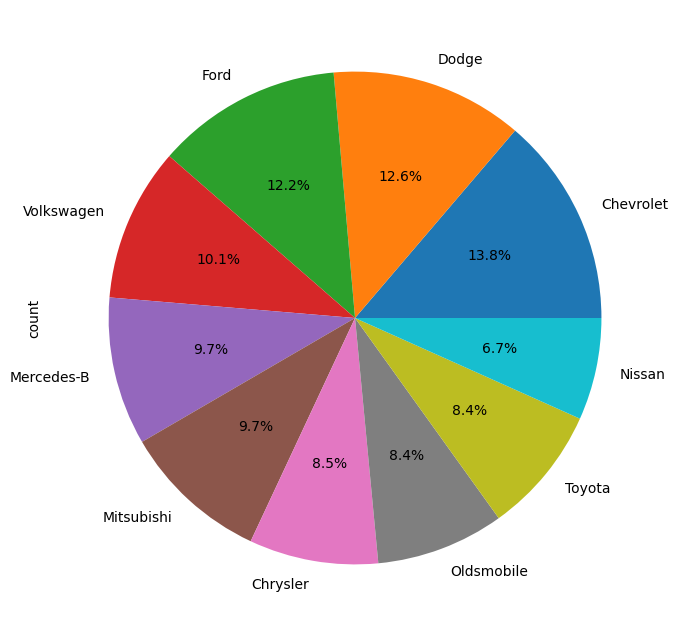

In [63]:
plt.figure(figsize=(10,8))
top_companies.plot(kind='pie',autopct='%0.1f%%')

In [64]:
df['company'].isnull().sum()

np.int64(0)

### color

**Conclusions**
- Pale white 47.1%
- Black 32.9%
- Red 20%

In [65]:
df['color'].value_counts()

color
Pale White    11256
Black          7857
Red            4793
Name: count, dtype: int64

<Axes: ylabel='count'>

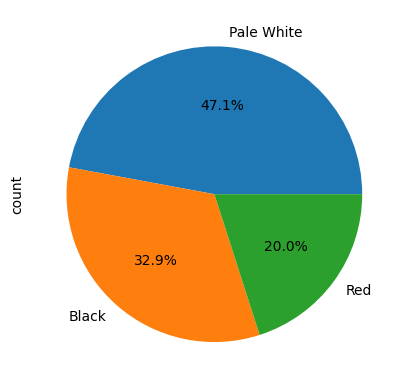

In [66]:
df['color'].value_counts().plot(kind='pie',autopct='%0.1f%%')

<Axes: xlabel='color'>

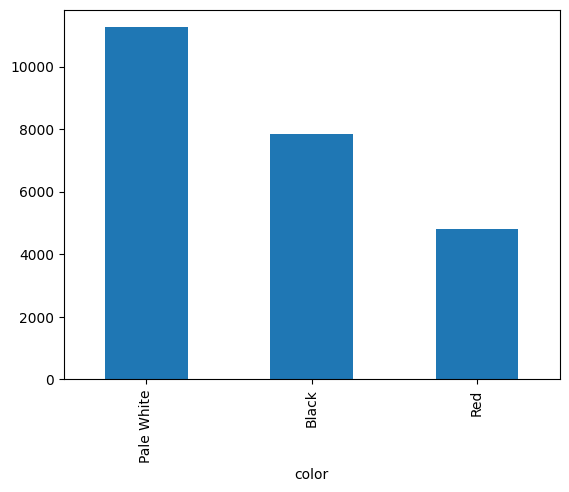

In [67]:
df['color'].value_counts().plot(kind='bar')

In [68]:
df['color'].isnull().sum()

np.int64(0)

### body_style

**Conclusions**
- SUV 26.7%
- Hatchback 25.6%
- Sedan 18.8%
- Passenger 16.5%
- Hardtop 12.4%

In [69]:
df['body_style'].value_counts()

body_style
SUV          6374
Hatchback    6128
Sedan        4488
Passenger    3945
Hardtop      2971
Name: count, dtype: int64

<Axes: ylabel='count'>

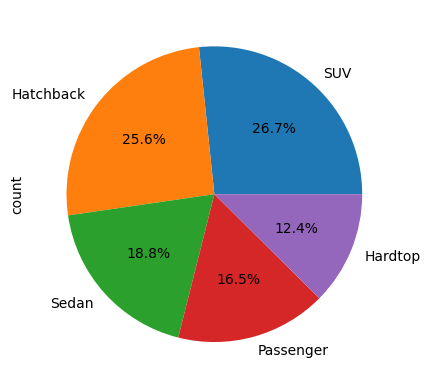

In [70]:
df['body_style'].value_counts().plot(kind='pie',autopct='%0.1f%%')

<Axes: xlabel='body_style'>

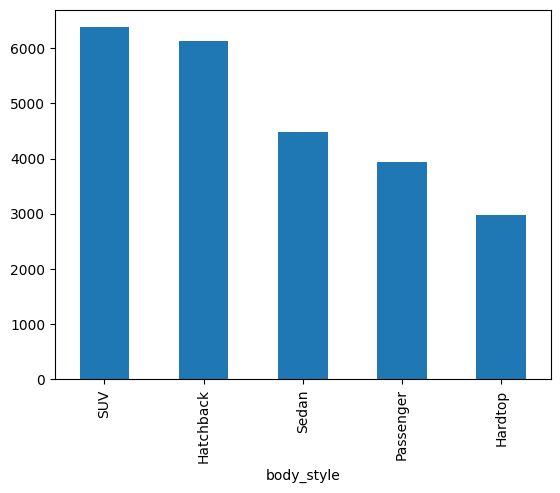

In [71]:
df['body_style'].value_counts().plot(kind='bar')

In [72]:
df['body_style'].isnull().sum()

np.int64(0)

### dealer rigion

**Conclusions**

In [73]:
df['dealer_region'].value_counts()

dealer_region
Austin        4135
Janesville    3821
Scottsdale    3433
Pasco         3131
Aurora        3130
Greenville    3128
Middletown    3128
Name: count, dtype: int64

<Axes: ylabel='count'>

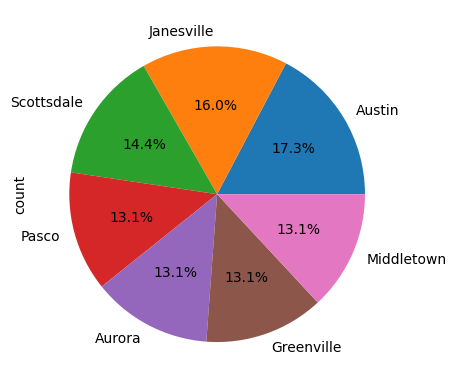

In [74]:
df['dealer_region'].value_counts().plot(kind='pie',autopct='%0.1f%%')

<Axes: xlabel='dealer_region'>

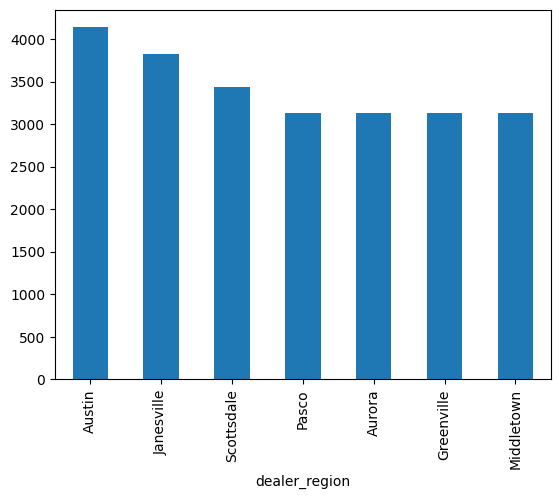

In [75]:
df['dealer_region'].value_counts().plot(kind='bar')

In [76]:
df['dealer_region'].isnull().sum()

np.int64(0)

### dealer name

**Conclusions**

In [77]:
df['dealer_name'].value_counts()

dealer_name
Progressive Shippers Cooperative Association No    1318
Rabun Used Car Sales                               1313
Race Car Help                                      1253
Saab-Belle Dodge                                   1251
Star Enterprises Inc                               1249
Tri-State Mack Inc                                 1249
Ryder Truck Rental and Leasing                     1248
U-Haul CO                                          1247
Scrivener Performance Engineering                  1246
Suburban Ford                                      1243
Nebo Chevrolet                                      633
Pars Auto Sales                                     630
New Castle Ford Lincoln Mercury                     629
McKinney Dodge Chrysler Jeep                        629
Hatfield Volkswagen                                 629
Gartner Buick Hyundai Saab                          628
Capitol KIA                                         628
Pitre Buick-Pontiac-Gmc of Scottsdal

<Axes: ylabel='count'>

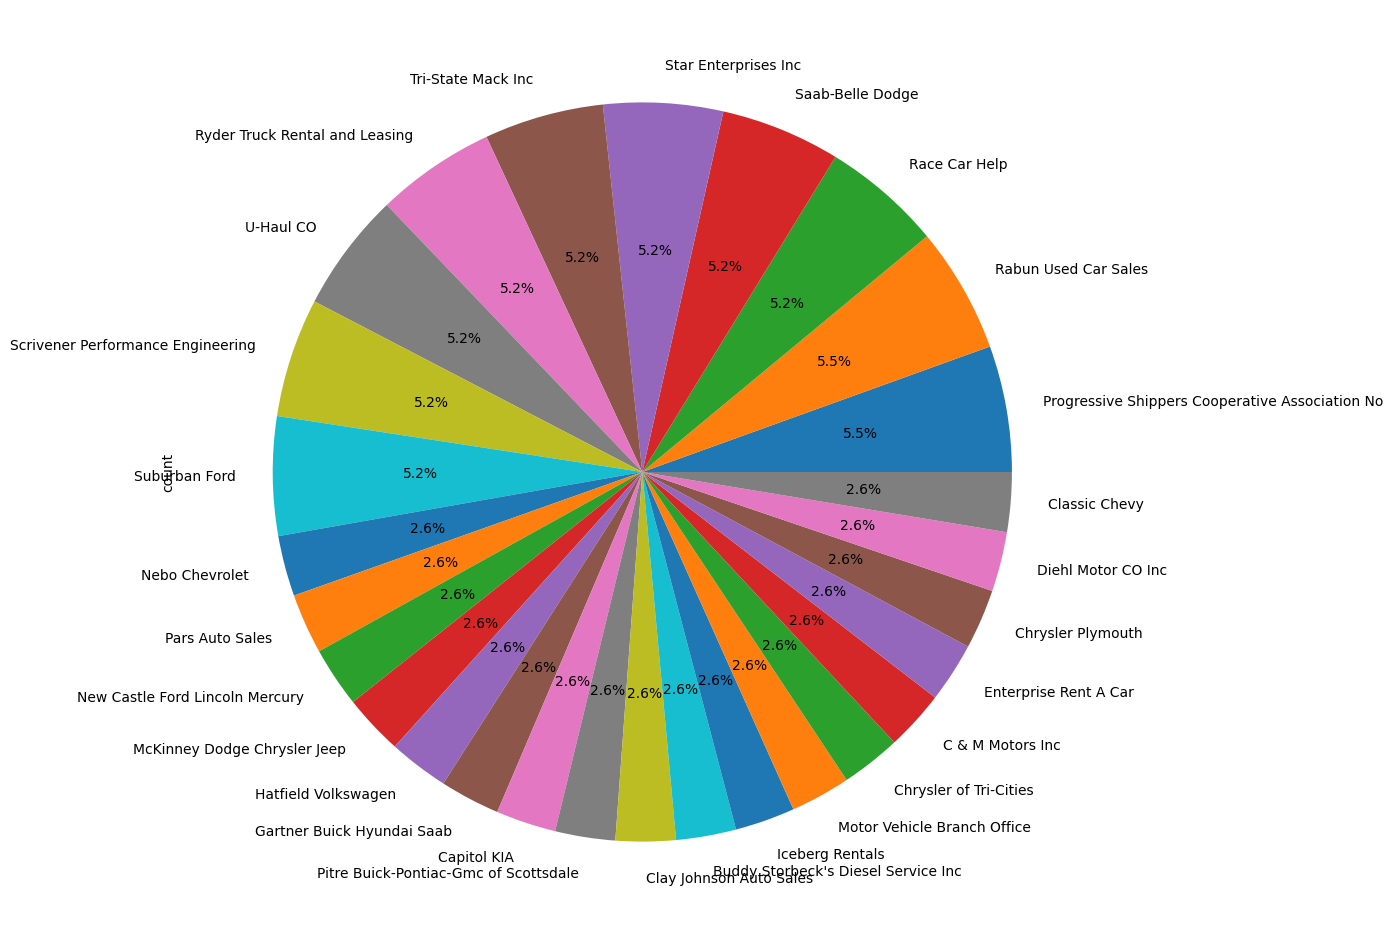

In [78]:
plt.figure(figsize=(12,12))
df['dealer_name'].value_counts().plot(kind='pie',autopct='%0.1f%%')

In [79]:
# top delaer names
top_dealer_names =df['dealer_name'].value_counts().head(10)

In [80]:
top_dealer_names

dealer_name
Progressive Shippers Cooperative Association No    1318
Rabun Used Car Sales                               1313
Race Car Help                                      1253
Saab-Belle Dodge                                   1251
Star Enterprises Inc                               1249
Tri-State Mack Inc                                 1249
Ryder Truck Rental and Leasing                     1248
U-Haul CO                                          1247
Scrivener Performance Engineering                  1246
Suburban Ford                                      1243
Name: count, dtype: int64

<Axes: ylabel='count'>

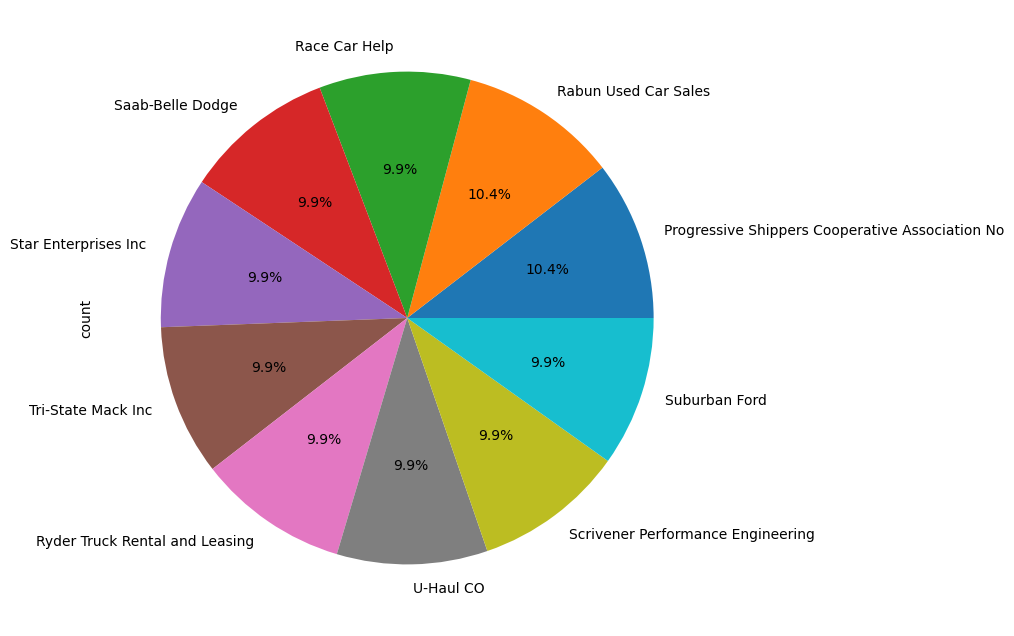

In [81]:
plt.figure(figsize=(10,8))
top_dealer_names.plot(kind='pie',autopct='%0.1f%%')

### Steps of doing Bivariate Analysis

- Select 2 cols
- Understand type of relationship
    1. **Numerical - Numerical**<br>
        a. You can plot graphs like scatterplot(regression plots), 2D histplot, 2D KDEplots<br>
        b. Check correlation coefficent to check linear relationship
    2. **Numerical - Categorical** - create visualizations that compare the distribution of the numerical data across different categories of the categorical data.<br>
        a. You can plot graphs like barplot, boxplot, kdeplot violinplot even scatterplots<br>
    3. **Categorical - Categorical**<br>
        a. You can create cross-tabulations or contingency tables that show the distribution of values in one categorical column, grouped by the values in the other categorical column.<br>
        b. You can plots like heatmap, stacked barplots, treemaps
        
- Write your conclusions

In [82]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 23906 entries, 0 to 23905
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   Car_id              23906 non-null  object        
 1   date                23906 non-null  datetime64[ns]
 2   customer_name       23906 non-null  object        
 3   gender              23906 non-null  object        
 4   annual_income       23906 non-null  int64         
 5   dealer_name         23906 non-null  object        
 6   company             23906 non-null  object        
 7   model               23906 non-null  object        
 8   engine              23906 non-null  object        
 9   transmission        23906 non-null  object        
 10  color               23906 non-null  object        
 11  price               23906 non-null  int64         
 12  Dealer_No           23906 non-null  object        
 13  body_style          23906 non-null  object    

### Numerical - Numerical Bivariate Analysis
**annual_income - price**
- Not linear relationship bewteen annual_income and price column

<Axes: xlabel='annual_income', ylabel='price'>

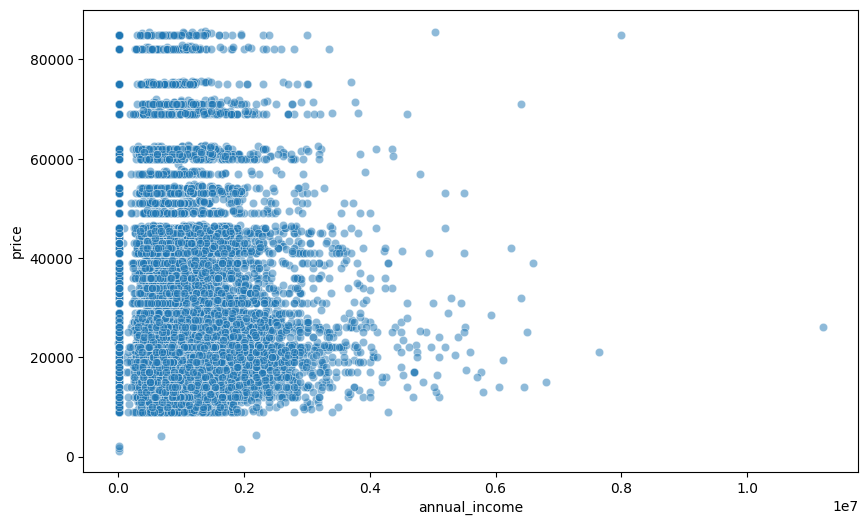

In [83]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df,x='annual_income',y='price',alpha=0.5)

In [84]:
#Pearson correlation
df[['annual_income','price']].corr()

,annual_income,price
annual_income,1,0
price,0,1


C:\Users\MD ARBAZ\AppData\Roaming\Python\Python313\site-packages\seaborn\relational.py:438: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  points = ax.scatter(x=x, y=y, **kws)


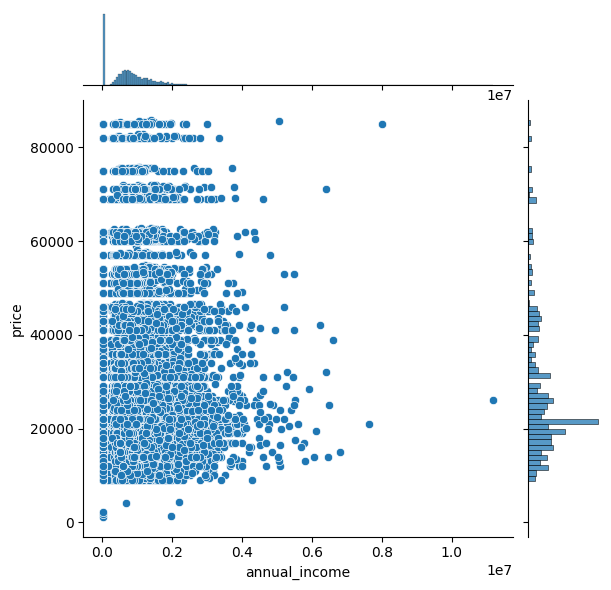

In [85]:
sns.jointplot(data=df,x='annual_income',y='price',cmap='mako')

### Categorical - Categorical Bivariate Analysis

**annual_segmentation - price_category**
 

In [86]:
pd.crosstab(df['annual_segmentaion'],df['price_category'],normalize='index')*100

price_category,Budget,Mid-Range,Expensive
annual_segmentaion,,,
Low Income,36,44,20
Medium Income,35,46,19
High Income,34,47,19


<Axes: xlabel='annual_segmentaion'>

<Figure size 1000x500 with 0 Axes>

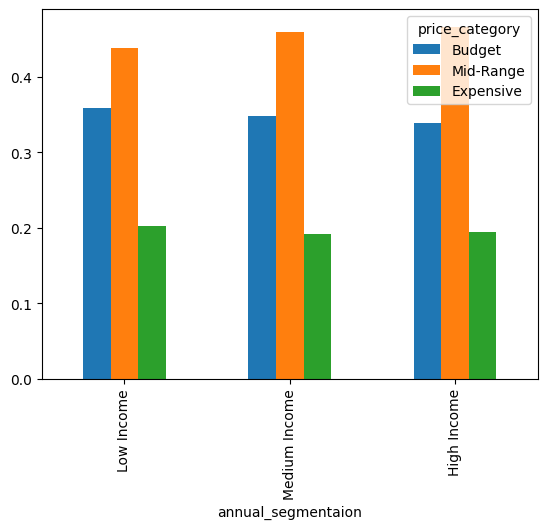

In [87]:
plt.figure(figsize=(10,5))
pd.crosstab(df['annual_segmentaion'],df['price_category'],normalize='index').plot(kind='bar')

### Categorical - Categorical

**price_category - gender**

In [88]:
pd.crosstab(df['price_category'],df['gender'])

gender,Female,Male
price_category,,
Budget,1788,6560
Mid-Range,2297,8573
Expensive,1023,3665


In [89]:
pd.crosstab(df['price_category'],df['gender'],normalize='index')*100

gender,Female,Male
price_category,,
Budget,21,79
Mid-Range,21,79
Expensive,22,78


<Axes: xlabel='price_category'>

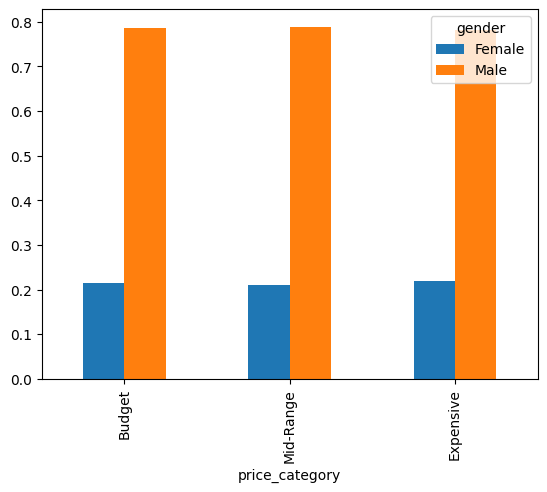

In [90]:
pd.crosstab(df['price_category'],df['gender'],normalize='index').plot(kind='bar')

C:\Users\MD ARBAZ\AppData\Local\Temp\ipykernel_3584\1410276115.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df,x='price_category',palette='Set2')


<Axes: xlabel='price_category', ylabel='count'>

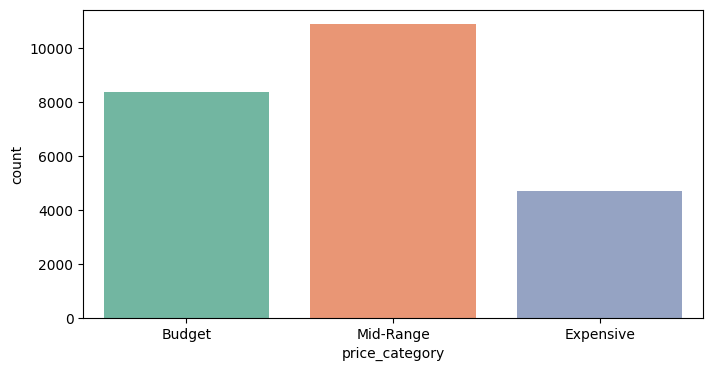

In [91]:
plt.figure(figsize=(8,4))
sns.countplot(data=df,x='price_category',palette='Set2')

C:\Users\MD ARBAZ\AppData\Local\Temp\ipykernel_3584\378450907.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df,x='annual_segmentaion',palette='Set2')


<Axes: xlabel='annual_segmentaion', ylabel='count'>

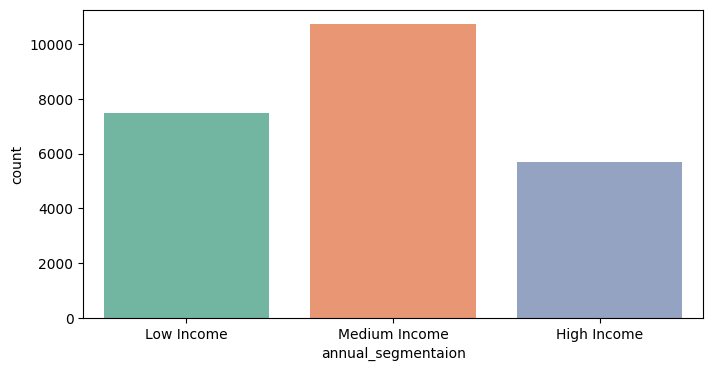

In [92]:
plt.figure(figsize=(8,4))
sns.countplot(data=df,x='annual_segmentaion',palette='Set2')

<Axes: xlabel='gender', ylabel='price_category'>

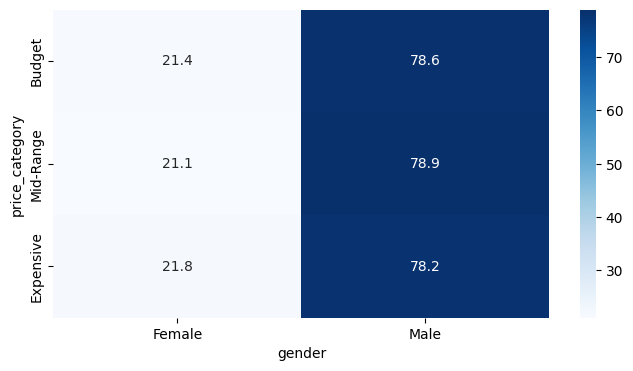

In [93]:
ct =pd.crosstab(df['price_category'],df['gender'],normalize='index')*100

plt.figure(figsize=(8,4))
sns.heatmap(ct,annot=True,cmap='Blues',fmt='.1f')


### Categorical - Categorical

**price_category - transmissions**

In [94]:
pd.crosstab(df['price_category'],df['transmission'])

transmission,Auto,Manual
price_category,,
Budget,4195,4153
Mid-Range,5936,4934
Expensive,2440,2248


In [95]:
pd.crosstab(df['price_category'],df['transmission'],normalize='index')*100

transmission,Auto,Manual
price_category,,
Budget,50,50
Mid-Range,55,45
Expensive,52,48


<Axes: xlabel='price_category'>

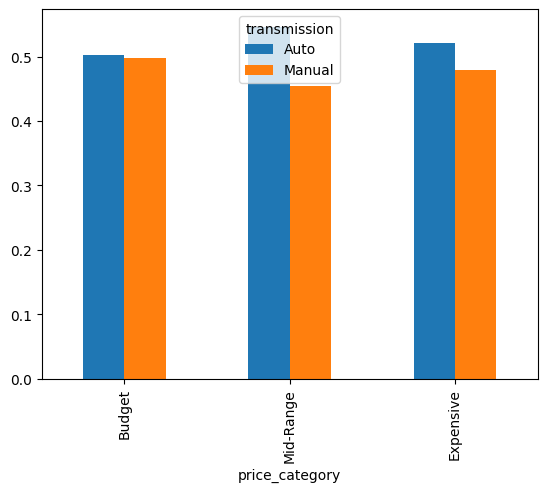

In [96]:
pd.crosstab(df['price_category'],df['transmission'],normalize='index').plot(kind='bar')

<Axes: xlabel='transmission', ylabel='price_category'>

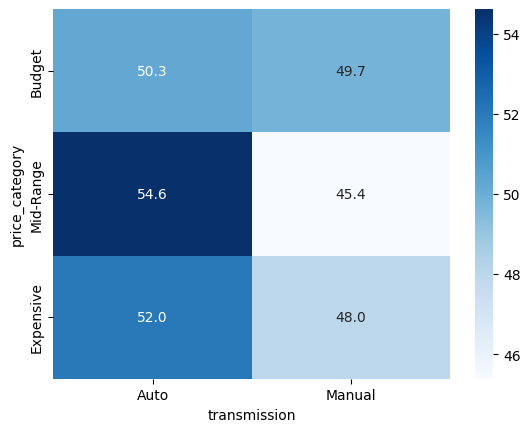

In [97]:
ht = pd.crosstab(df['price_category'],df['transmission'],normalize='index')*100

sns.heatmap(ht,annot=True,cmap='Blues',fmt='.1f')

### Categorical - Categorical

**price_category - dealer_region**

In [98]:
pd.crosstab(df['price_category'],df['dealer_region'])

dealer_region,Aurora,Austin,Greenville,Janesville,Middletown,Pasco,Scottsdale
price_category,,,,,,,
Budget,1084,1398,1118,1327,1105,1072,1244
Mid-Range,1409,1900,1392,1763,1433,1450,1523
Expensive,637,837,618,731,590,609,666


In [99]:
pd.crosstab(df['price_category'],df['dealer_region'],normalize='index')*100

dealer_region,Aurora,Austin,Greenville,Janesville,Middletown,Pasco,Scottsdale
price_category,,,,,,,
Budget,13,17,13,16,13,13,15
Mid-Range,13,17,13,16,13,13,14
Expensive,14,18,13,16,13,13,14


<Axes: xlabel='price_category'>

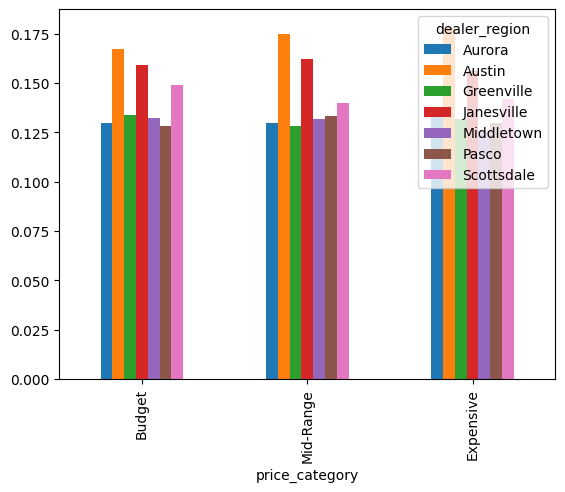

In [100]:
pd.crosstab(df['price_category'],df['dealer_region'],normalize='index').plot(kind='bar')

<Axes: xlabel='dealer_region', ylabel='price_category'>

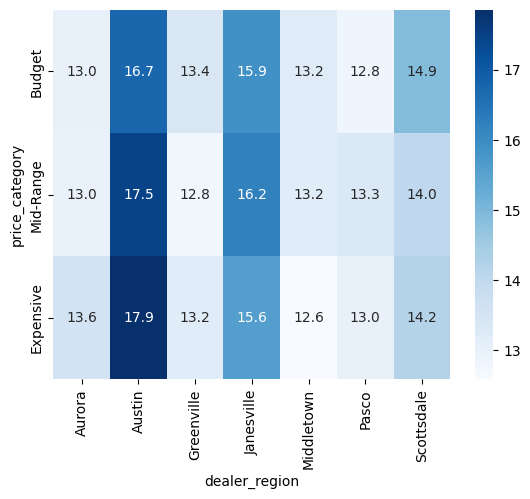

In [101]:
pr = pd.crosstab(df['price_category'],df['dealer_region'],normalize='index')*100

sns.heatmap(pr,annot=True,cmap='Blues',fmt='.1f')

### Categorical - Categorical

**price_category - body_style**

In [102]:
pd.crosstab(df['price_category'],df['body_style'])

body_style,Hardtop,Hatchback,Passenger,SUV,Sedan
price_category,,,,,
Budget,793,2337,1491,2218,1509
Mid-Range,1502,2729,1632,3130,1877
Expensive,676,1062,822,1026,1102


In [103]:
pd.crosstab(df['price_category'],df['body_style'],normalize='index')*100

body_style,Hardtop,Hatchback,Passenger,SUV,Sedan
price_category,,,,,
Budget,9,28,18,27,18
Mid-Range,14,25,15,29,17
Expensive,14,23,18,22,24


<Axes: xlabel='price_category'>

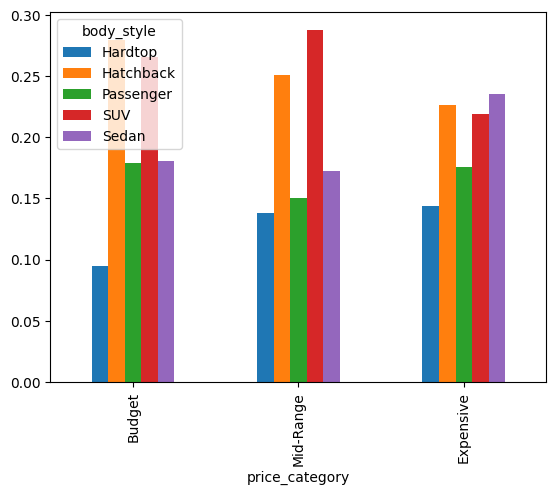

In [104]:
pd.crosstab(df['price_category'],df['body_style'],normalize='index').plot(kind='bar')

### Categorical - Categorical

**price_category - company**

In [105]:
pd.crosstab(df['price_category'],df['company'])

company,Acura,Audi,BMW,Buick,Cadillac,Chevrolet,Chrysler,Dodge,Ford,Honda,...,Oldsmobile,Plymouth,Pontiac,Porsche,Saab,Saturn,Subaru,Toyota,Volkswagen,Volvo
price_category,,,,,,,,,,,,,,,,,,,,,
Budget,253,227,354,178,34,646,410,492,613,162,...,374,212,387,99,25,216,105,260,482,217
Mid-Range,389,181,337,88,396,797,458,966,517,364,...,400,317,145,262,125,190,219,651,699,477
Expensive,47,60,99,173,222,376,252,213,484,182,...,337,88,264,0,60,180,81,199,152,95


In [106]:
top_company =df['company'].value_counts().head(10).index
pd.crosstab(df['price_category'],df['company'])[top_company]

company,Chevrolet,Dodge,Ford,Volkswagen,Mercedes-B,Mitsubishi,Chrysler,Oldsmobile,Toyota,Nissan
price_category,,,,,,,,,,
Budget,646,492,613,482,529,502,410,374,260,349
Mid-Range,797,966,517,699,583,555,458,400,651,389
Expensive,376,213,484,152,173,220,252,337,199,148


<Axes: xlabel='price_category'>

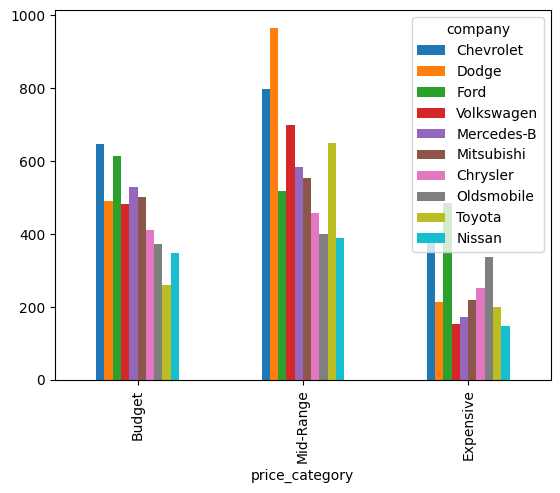

In [107]:
pd.crosstab(df['price_category'],df['company'])[top_company].plot(kind='bar')

- Column Type

- Numerical - price , annual_income, phone

- Categorical - price_category, annual_segmentation, gender, engine,transmission, company , color, body_style, delear_region, dealer_name

- Mixed Column - Car_id, date , dealer_no


### Numerical - Categorical 

**Price - Gender**

**Conclusions**
- male and female are purchase car is equal price

<Axes: xlabel='gender', ylabel='price'>

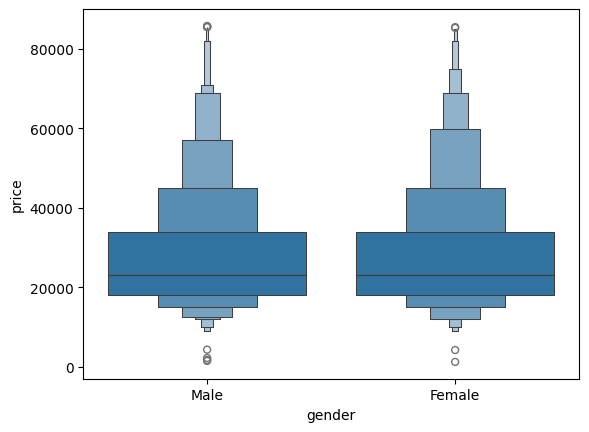

In [109]:
sns.boxenplot(data=df,x='gender',y='price')

<Axes: xlabel='gender', ylabel='price'>

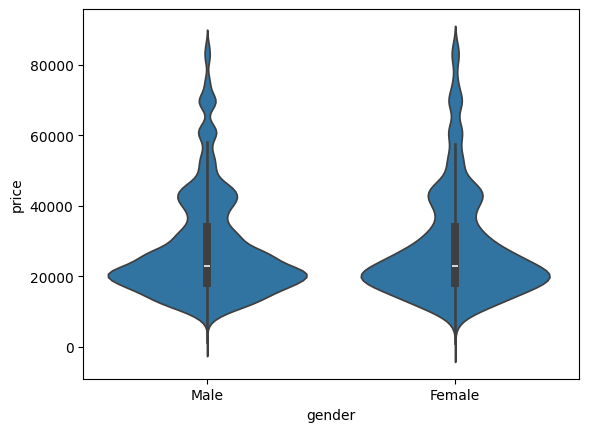

In [110]:
sns.violinplot(data=df,x='gender',y='price')

<Axes: xlabel='gender', ylabel='price'>

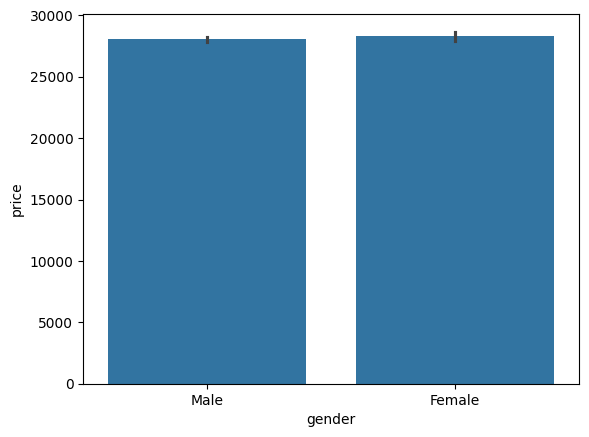

In [111]:
sns.barplot(data=df,x='gender',y='price')

<Axes: xlabel='gender', ylabel='price'>

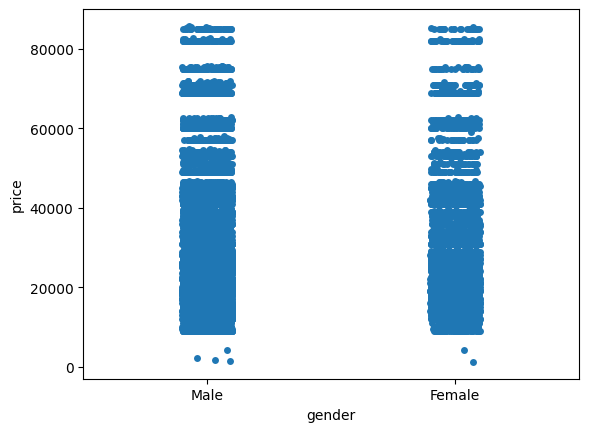

In [112]:
sns.stripplot(data=df,x='gender',y='price')

### Annual Income - Gender

**Conclusions**
- 1. male income > female income

<Axes: xlabel='gender', ylabel='annual_income'>

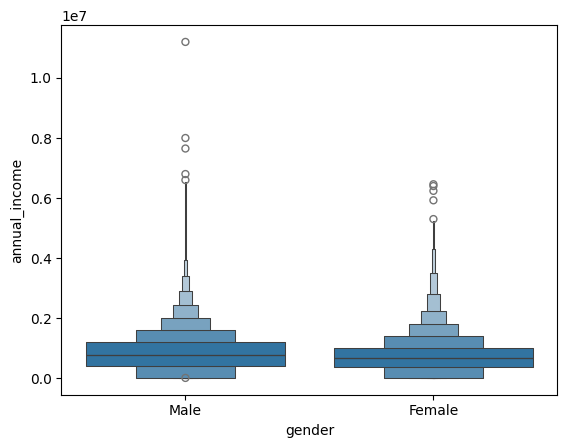

In [113]:
sns.boxenplot(data=df,x='gender',y='annual_income')

<Axes: xlabel='gender', ylabel='annual_income'>

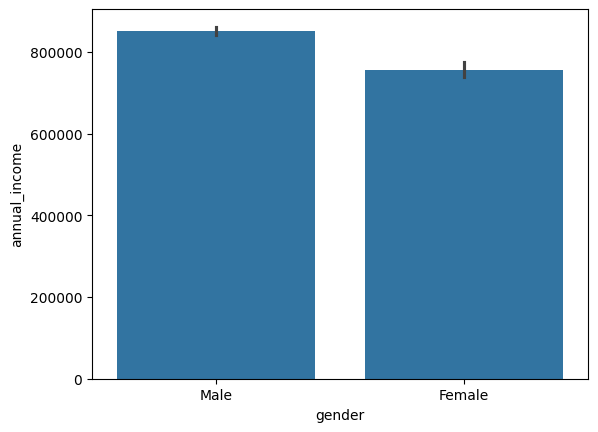

In [114]:
sns.barplot(data=df,x='gender',y='annual_income')

<Axes: xlabel='gender', ylabel='annual_income'>

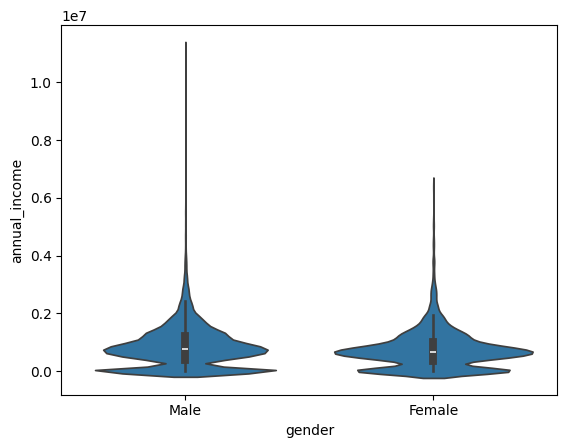

In [115]:
sns.violinplot(data=df,x='gender',y='annual_income')

### Price - Color

**Conclusions**

- red color car is a bit expensive than black color car and pale white color car is cheapset than red and black

<Axes: xlabel='color', ylabel='price'>

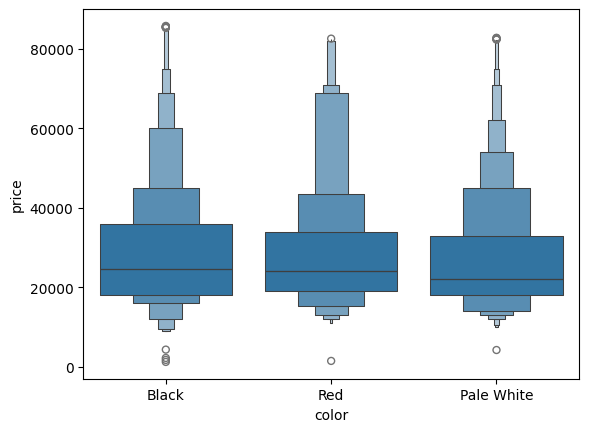

In [116]:
sns.boxenplot(data=df,x='color',y='price')

<Axes: xlabel='color', ylabel='price'>

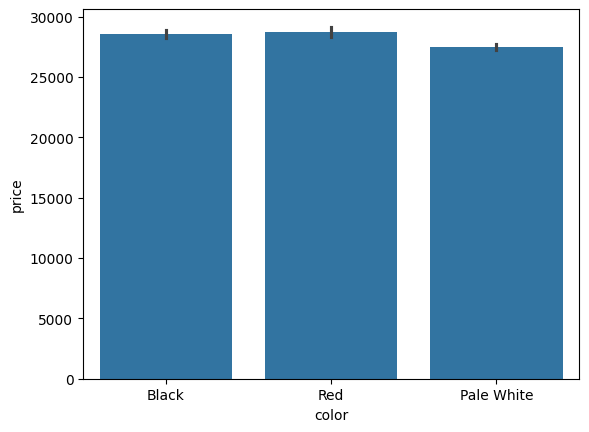

In [117]:
sns.barplot(data=df,x='color',y='price')

<Axes: xlabel='color', ylabel='price'>

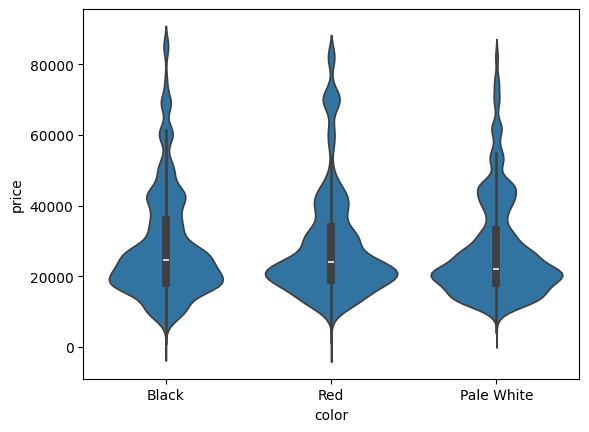

In [118]:
sns.violinplot(data=df,x='color',y='price')

In [124]:
df

,Car_id,date,customer_name,gender,annual_income,dealer_name,company,model,engine,transmission,color,price,Dealer_No,body_style,phone,dealer_region,annual_segmentaion,price_category
0,C_CND_000001,2022-01-02,Geraldine,Male,13500,Buddy Storbeck's Diesel Service Inc,Ford,Expedition,Double Overhead Camshaft,Auto,Black,26000,06457-3834,SUV,8264678,Middletown,Low Income,Mid-Range
1,C_CND_000002,2022-01-02,Gia,Male,1480000,C & M Motors Inc,Dodge,Durango,Double Overhead Camshaft,Auto,Black,19000,60504-7114,SUV,6848189,Aurora,High Income,Budget
2,C_CND_000003,2022-01-02,Gianna,Male,1035000,Capitol KIA,Cadillac,Eldorado,Overhead Camshaft,Manual,Red,31500,38701-8047,Passenger,7298798,Greenville,Medium Income,Mid-Range
3,C_CND_000004,2022-01-02,Giselle,Male,13500,Chrysler of Tri-Cities,Toyota,Celica,Overhead Camshaft,Manual,Pale White,14000,99301-3882,SUV,6257557,Pasco,Low Income,Budget
4,C_CND_000005,2022-01-02,Grace,Male,1465000,Chrysler Plymouth,Acura,TL,Double Overhead Camshaft,Auto,Red,24500,53546-9427,Hatchback,7081483,Janesville,High Income,Mid-Range
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
23901,C_CND_023902,2023-12-31,Martin,Male,13500,C & M Motors Inc,Plymouth,Voyager,Overhead Camshaft,Manual,Red,12000,60504-7114,Passenger,8583598,Pasco,Low Income,Budget
23902,C_CND_023903,2023-12-31,Jimmy,Female,900000,Ryder Truck Rental and Leasing,Chevrolet,Prizm,Double Overhead Camshaft,Auto,Black,16000,06457-3834,Hardtop,7914229,Middletown,Medium Income,Budget
23903,C_CND_023904,2023-12-31,Emma,Male,705000,Chrysler of Tri-Cities,BMW,328i,Overhead Camshaft,Manual,Red,21000,99301-3882,Sedan,7659127,Scottsdale,Medium Income,Mid-Range
23904,C_CND_023905,2023-12-31,Victoire,Male,13500,Chrysler Plymouth,Chevrolet,Metro,Double Overhead Camshaft,Auto,Black,31000,53546-9427,Passenger,6030764,Austin,Low Income,Mid-Range


In [125]:
df.to_csv("car_data.csv",index=False)